# 3-fish recording: scaling the emitted current with body length, $A \propto L^e$

My model as in `EOD_assignment_3_fish_conductivities.ipynb`: BEM conductivities (interior 100 × water, skin 0.05 × water over
0.005 cm), sink at the tail tip, sign fixed (model × −1). The field is linear in the current, so fish $f$'s model voltages for an
exponent $e$ are $m_f = -L_f^{e}\,u_f$, with $u_f$ the cached unit-current voltages (no new solves). As in section 6 of
`EOD_assignment_2_fish_silent.ipynb` (2-fish, earlier conductivities: e = 0 best), now on the 3-fish recording, where the emitter
(fish 0) is the **smallest** fish.

**Body length $L_f$**: one fixed length per fish, measured as in `fish_lengths.py` (which covers only the 4-fish recordings) on this
recording's ZEUS masks: every 5th frame, clean masks (one piece, area within 10% of the fish's median, ≥ 10 px from the image edge,
not within 3 px of another fish); the midlines of the 300 most elongated; L = median length of the 30 straightest (≤ 2.5 px from the
tip-to-tip line). Saved to `results/eod_ground_truth_3fish/fish_lengths_3fish.json`.

**Rules** (recorded peak pattern $r$, 10 pairs; smallest distance wins):
1. **shape only** (current pipeline): $r$ and each $m_f$ scaled to max |v| = 1 on their own; $L_f^e$ cancels, so every e gives the
   same picks.
2. **joint max = 1**: $r$ scaled to max |v| = 1; all fish's $m_f$ scaled by one common factor so the largest |v| over all fish and
   pairs is 1. Relative amplitudes kept, but the reference is whichever model fish is largest in that frame, not the recording.
3. **amplitude kept, self-calibrated gain**: $d_f = \lVert r - g\,m_f\rVert$ on the raw recorded volts, with one gain $g$
   (model units → volts) shared by all fish, so each fish is compared at the amplitude it would produce. $g$ is estimated
   **without the ground truth**: start from the shape-only picks; $g$ = median over EODs of the least-squares gain
   $r\cdot m_{f^*}/\lVert m_{f^*}\rVert^2$ of the picked fish $f^*$; re-pick; repeat until the picks stop changing.
   - **3a, one g** for the whole recording;
   - **3b, rolling g**: median over the 501 EODs nearest in time (follows slow drift of the EOD amplitude).

Rule 3's total residual also gives a choice of e that does not use the ground truth: the e whose picked fish explain the recordings
best (smallest median relative residual $\lVert r - g\,m_{f^*}\rVert / \lVert r\rVert$).

Two sets of EODs: all 19,796 and the better list of good frames (6,751). EODs where a fish has no model (no mask or midline) leave
that fish out; if fish 0 has none the EOD counts as wrong. e < 0 (smaller fish emits more current) is shown only as a check: it
favours fish 0 here simply because fish 0 is the smallest.

In [1]:
import json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import label
import mask_metrics as mm_q
import midline_methods as mm
from fish_lengths import elongation
%matplotlib inline

DATA, RES = 'data/3_fish_silent', 'results/eod_ground_truth_3fish'
OUT = f'{RES}/conductivities'
FISH, EMITTER = (0, 1, 2), 0
STRIDE, CONTACT_GAP, AREA_TOL, EDGE_PX, N_CANDIDATES, MAX_DEV_PX, N_USE = 5, 3, 0.10, 10, 300, 2.5, 30   # as fish_lengths.py
E_ASKED = [0, 0.5, 1, 1.5, 2]
E_GRID = np.round(np.arange(-1, 3.01, 0.25), 2)
ROLL = 501

with open(f'{DATA}/elephantnose_20241015T141225_tracking_final.pkl', 'rb') as f:
    trk = pickle.load(f)
frames, P = trk['frames'], trk['shape'][0]

## Body length of each fish

In [2]:
def masks_of(k):
    '''Full-frame bool mask of each fish in frame k (None if missing or duplicated).'''
    fr = frames[k]; out = [None] * len(FISH)
    labs = list(fr['labels'])
    for l, p, b in zip(labs, fr['masks'], fr['boxes']):
        if l in FISH and labs.count(l) == 1:
            m = np.zeros((P, P), bool); m[b[0]:b[1], b[2]:b[3]] = mm_q.unpack_crop(p, b); out[l] = m
    return out

ks = sorted(frames)[::STRIDE]
area = pd.DataFrame([{l: a for l, a in zip(frames[k]['labels'], frames[k]['areas'])} for k in sorted(frames)])
med_area = {f: area[f].median() for f in FISH}
cand = {f: [] for f in FISH}
for k in ks:
    ms = masks_of(k)
    contact, _ = mm.contact_frames(lambda _k: ms, [k], gap=CONTACT_GAP)
    for f in FISH:
        m = ms[f]
        if m is None or contact[0, f] or abs(m.sum() / med_area[f] - 1) > AREA_TOL: continue
        r, c = np.nonzero(m)
        if min(r.min(), c.min(), P - 1 - r.max(), P - 1 - c.max()) < EDGE_PX: continue
        if label(m, structure=np.ones((3, 3)))[1] != 1: continue
        cand[f].append((elongation(m), k))

lengths = {}
for f in FISH:
    rows = []
    for _, k in sorted(cand[f], reverse=True)[:N_CANDIDATES]:
        px = mm.fish_midline_with_head(masks_of(k)[f])['midline'] * (P - 1)
        u = (px[-1] - px[0]) / np.linalg.norm(px[-1] - px[0]); d = px - px[0]
        rows.append(dict(frame=k, L_px=np.linalg.norm(np.diff(px, axis=0), axis=1).sum(), dev=np.abs(d[:, 0] * u[1] - d[:, 1] * u[0]).max()))
    use = sorted([r for r in rows if r['dev'] <= MAX_DEV_PX], key=lambda r: r['dev'])[:N_USE]
    Ls = np.array([r['L_px'] for r in use])
    lengths[f] = dict(L_px=round(float(np.median(Ls)), 3), L_tank=round(float(np.median(Ls)) / (P - 1), 6), n_frames_used=len(use),
                      L_px_range=[round(float(Ls.min()), 2), round(float(Ls.max()), 2)], clean_candidates=len(cand[f]),
                      frames_used=[int(r['frame']) for r in use])
json.dump(dict(recording='2024-10-15T14_12_25 (3-fish)', units='L_tank = L_px / (P - 1)', fish=lengths,
               method='fish_lengths.py rules on the ZEUS masks'), open(f'{RES}/fish_lengths_3fish.json', 'w'), indent=1)
L = np.array([lengths[f]['L_tank'] for f in FISH])
display(pd.DataFrame(lengths).T[['L_px', 'L_tank', 'n_frames_used', 'L_px_range', 'clean_candidates']].assign(
    L_cm=lambda t: (t.L_px / (912 / 60)).astype(float).round(2), ratio_to_fish0=L / L[0]))

,L_px,L_tank,n_frames_used,L_px_range,clean_candidates,L_cm,ratio_to_fish0
0,180.786,0.198448,27,"[160.22, 185.55]",4062,11.89,1.000000
1,251.485,0.276054,5,"[242.48, 256.65]",3823,16.55,1.391065
2,213.44,0.234292,2,"[209.42, 217.46]",4546,14.04,1.180622


## Assignments for every e and rule

In [3]:
A = pd.read_csv(f'{OUT}/eod_assignments.csv', index_col='row')
cache = pd.read_pickle(f'{OUT}/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl')
assert (cache.frame.to_numpy() == A.Frame.to_numpy()).all()
R = np.stack(cache.v_rec.map(np.asarray))                                  # (n, 10) recorded peak pattern, volts
U = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))           # (n, 3, 10) unit-current model, sign fixed
ok = np.isfinite(U).all(axis=2)                                            # (n, 3) fish has a model
order = np.argsort(cache.time.to_numpy(), kind='stable')                    # time order for the rolling gain
better = A.Frame.isin(pd.read_csv(f'{RES}/good_frames_better_list.csv').frame).to_numpy()
SETS = {'all EODs': np.ones(len(A), bool), 'better list of good frames': better}

def pick(d):
    d = np.where(ok, d, np.inf); p = d.argmin(axis=1); return np.where(np.isfinite(d.min(axis=1)), p, -1)

def unit_max(x): return x / np.abs(x).max(axis=-1, keepdims=True)

Rh = unit_max(R)
shape_pick = pick(np.linalg.norm(Rh[:, None] - unit_max(U), axis=2))
assert (shape_pick == A['fish | BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip'].fillna(-1).to_numpy()).mean() > 0.999

def joint(M):
    c = 1 / np.nanmax(np.abs(np.where(ok[..., None], M, np.nan)), axis=(1, 2))
    return pick(np.linalg.norm(Rh[:, None] - c[:, None, None] * M, axis=2))

def amplitude(M, rolling, max_iter=30):
    p = shape_pick.copy()
    for it in range(max_iter):
        idx = np.clip(p, 0, None); m = M[np.arange(len(M)), idx]
        gi = pd.Series(np.where(p >= 0, (R * m).sum(1) / (m * m).sum(1), np.nan))
        g = (gi.iloc[order].rolling(ROLL, center=True, min_periods=1).median().reindex(gi.index).to_numpy() if rolling
             else np.full(len(M), np.nanmedian(gi)))
        d = np.linalg.norm(R[:, None] - g[:, None, None] * M, axis=2); new = pick(d)
        if (new == p).all(): break
        p = new
    idx = np.clip(p, 0, None)
    rel = d[np.arange(len(M)), idx] / np.linalg.norm(R, axis=1)
    return p, np.nanmedian(g), np.nanmedian(np.where(p >= 0, rel, np.nan)), it + 1

rows = []
for e in E_GRID:
    M = U * (L ** e)[None, :, None]
    picks = {'1. shape only': shape_pick, '2. joint max = 1': joint(M)}
    for nm, roll in (('3a. amplitude, one g', False), ('3b. amplitude, rolling g', True)):
        picks[nm], g, res, n_it = amplitude(M, roll)
        rows.append(dict(e=e, rule=nm, measure='calibrated g (median)', value=g))
        rows.append(dict(e=e, rule=nm, measure='median relative residual', value=res))
        rows.append(dict(e=e, rule=nm, measure='iterations', value=n_it))
    for nm, p in picks.items():
        for s, m in SETS.items():
            rows.append(dict(e=e, rule=nm, measure=f'% correct, {s}', value=100 * (p[m] == EMITTER).mean()))
            rows.append(dict(e=e, rule=nm, measure=f'% to fish 1, {s}', value=100 * (p[m] == 1).mean()))
            rows.append(dict(e=e, rule=nm, measure=f'% to fish 2, {s}', value=100 * (p[m] == 2).mean()))
T = pd.DataFrame(rows)
T.to_csv(f'{OUT}/length_scaling_exponents.csv', index=False)
acc = T[T.measure.str.startswith('% correct')].pivot_table(index='e', columns=['measure', 'rule'], values='value')
display(acc.loc[E_ASKED].round(2))

measure % correct, all EODs                                        \
rule          1. shape only 2. joint max = 1 3a. amplitude, one g   
e                                                                   
0.0                   86.55            84.04                88.56   
0.5                   86.55            83.30                89.62   
1.0                   86.55            82.31                90.53   
1.5                   86.55            81.09                91.51   
2.0                   86.55            79.67                92.45   

measure                          % correct, better list of good frames  \
rule    3b. amplitude, rolling g                         1. shape only   
e                                                                        
0.0                        88.57                                  94.5   
0.5                        89.56                                  94.5   
1.0                        90.44                                  94.5   
1.5                        91.23                                  94.5   
2.0                        92.07                                  94.5   

measure                                                                 
rule    2. joint max = 1 3a. amplitude, one g 3b. amplitude, rolling g  
e                                                                       
0.0                91.62                97.38                    97.26  
0.5                90.24                97.75                    97.67  
1.0                88.36                97.88                    97.85  
1.5                86.52                98.16                    98.12  
2.0                84.42                98.52                    98.47

## % correct against the exponent

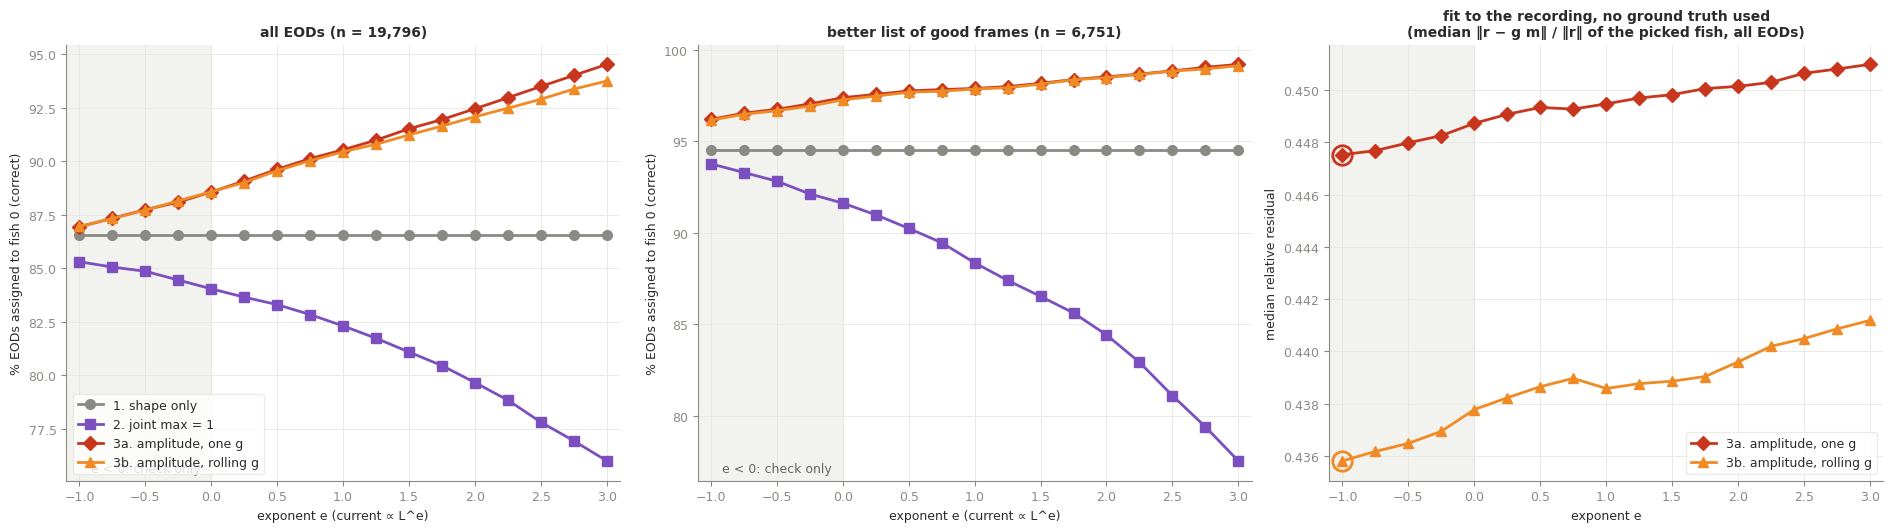

In [4]:
COL = {'1. shape only': '#8a8a85', '2. joint max = 1': '#7B4FBF', '3a. amplitude, one g': '#C8361E', '3b. amplitude, rolling g': '#F08A24'}
MK = {'1. shape only': 'o', '2. joint max = 1': 's', '3a. amplitude, one g': 'D', '3b. amplitude, rolling g': '^'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3'})
fig, axs = plt.subplots(1, 3, figsize=(19, 5.4))
for a, s in zip(axs, SETS):
    for nm in COL:
        t = T[(T.rule == nm) & (T.measure == f'% correct, {s}')]
        a.plot(t.e, t.value, color=COL[nm], marker=MK[nm], ms=7, lw=2, label=nm)
    a.axvspan(E_GRID[0] - 0.1, 0, color='#f2f2ef', zorder=0); a.text(-0.5, 0.02, 'e < 0: check only', transform=a.get_xaxis_transform(), ha='center', fontsize=9, color='0.4')
    a.set(title=f'{s} (n = {SETS[s].sum():,})', xlabel='exponent e (current ∝ L^e)', ylabel='% EODs assigned to fish 0 (correct)', xlim=(E_GRID[0] - 0.1, E_GRID[-1] + 0.1))
axs[0].legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#e6e6e3')
a = axs[2]
for nm in ('3a. amplitude, one g', '3b. amplitude, rolling g'):
    t = T[(T.rule == nm) & (T.measure == 'median relative residual')]
    a.plot(t.e, t.value, color=COL[nm], marker=MK[nm], ms=7, lw=2, label=nm)
    b = t.loc[t.value.idxmin()]; a.plot(b.e, b.value, 'o', ms=14, mfc='none', mec=COL[nm], mew=2)
a.axvspan(E_GRID[0] - 0.1, 0, color='#f2f2ef', zorder=0)
a.set(title='fit to the recording, no ground truth used\n(median ‖r − g m‖ / ‖r‖ of the picked fish, all EODs)', xlabel='exponent e', ylabel='median relative residual', xlim=(E_GRID[0] - 0.1, E_GRID[-1] + 0.1))
a.legend(frameon=True, facecolor='white', edgecolor='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/figures/length_scaling_exponents.png', dpi=120); plt.show()

## Where the picks go, for the asked exponents

In [5]:
m = T[T.e.isin(E_ASKED) & T.measure.str.contains('better list') & (T.rule != '1. shape only')]
display(m.assign(measure=m.measure.str.replace(', better list of good frames', '')).pivot_table(index=['rule', 'e'], columns='measure', values='value').round(2))

measure                       % correct  % to fish 1  % to fish 2
rule                     e                                       
2. joint max = 1         0.0      91.62         2.37         6.01
                         0.5      90.24         2.56         7.20
                         1.0      88.36         2.80         8.84
                         1.5      86.52         3.29        10.19
                         2.0      84.42         4.06        11.52
3a. amplitude, one g     0.0      97.38         0.41         2.21
                         0.5      97.75         0.39         1.87
                         1.0      97.88         0.33         1.79
                         1.5      98.16         0.27         1.57
                         2.0      98.52         0.25         1.23
3b. amplitude, rolling g 0.0      97.26         0.44         2.30
                         0.5      97.67         0.37         1.96
                         1.0      97.85         0.31         1.84
                         1.5      98.12         0.24         1.64
                         2.0      98.47         0.16         1.36